<a href="https://colab.research.google.com/github/isaacgrindley/quantum-circuit-simulator/blob/main/QECMini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First we implement a qubit register using the standard linear algebra methods, alongside some basic gates and a simple measurement system.

In [125]:
import numpy as np
import matplotlib.pyplot as plt
from math import *
from collections import Counter


def qReg(k):
  qbit = np.zeros((2**k,1))
  qbit[(0,0)] = 1
  return qbit

def measure(reg,n):
  probs = abs(reg)**2
  result = []
  for i in range(n):
    iresult = int(np.random.choice(range(len(reg)),p = probs[:,0]))
    result.append(iresult)
  return result

def plotMeasure(reg,n):
  plt.hist(measure(reg,n),np.array(range(len(reg)+1))-0.5)
  labels = []
  for i in range(len(reg)):
    labels.append(np.binary_repr(i,int(log2(len(reg)))))
  plt.xticks(range(len(reg)),labels)
  plt.show
  return

def H(reg,i):
  H = 1/sqrt(2) * np.array([[1,1],[1,-1]])
  multiH = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiH = np.kron(multiH,H)
    else:
      multiH = np.kron(multiH,[[1,0],[0,1]])
  return multiH @ reg

def X(reg,i):
  X = np.array([[0,1],[1,0]])
  multiX = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiX = np.kron(multiX,X)
    else:
      multiX = np.kron(multiX,[[1,0],[0,1]])
  return multiX @ reg

def Y(reg,i):
  Y = np.array([[0,1],[-1,0]])
  multiY = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiY = np.kron(multiY,Y)
    else:
      multiY = np.kron(multiY,[[1,0],[0,1]])
  return multiY @ reg

def Z(reg,i):
  Z = np.array([[1,0],[0,-1]])
  multiZ = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiZ = np.kron(multiZ,Z)
    else:
      multiZ = np.kron(multiZ,[[1,0],[0,1]])
  return multiZ @ reg

def CX(reg,i,j):
  proj1 = np.array([[1]])
  proj2 = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      proj1 = np.kron(proj1,[[1,0],[0,0]])
      proj2 = np.kron(proj2,[[0,0],[0,1]])
    elif k == j:
      proj1 = np.kron(proj1,[[1,0],[0,1]])
      proj2 = np.kron(proj2,[[0,1],[1,0]])
    else:
      proj1 = np.kron(proj1,[[1,0],[0,1]])
      proj2 = np.kron(proj2,[[1,0],[0,1]])
    multiCX = proj1 + proj2
  return multiCX @ reg

Now we can create a Bell state and do some measurements to test our simulator.

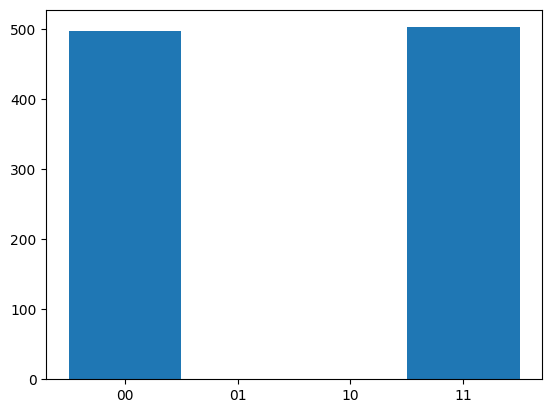

In [2]:
bell1 = qReg(2)
bell1 = CX(H(bell1,0),0,1)



plotMeasure(bell1,1000)

Now let's explore some basic error correction with encoding a single quibit into three.

In [229]:
alpha = 0.776
beta = sqrt(1-alpha**2)
qin = np.array([[alpha],[beta]])

def encode3(qbit):
  reg = np.kron(qReg(1),np.kron(qReg(1),qbit))
  # tensor products two 0 qubits to the qubit to make a 3-qubit register
  result = CX(reg,2,0)
  result = CX(result,2,1)
  return result

def flipBits(reg):
  p = 0.5
  flipprobs = np.random.rand(3)
  for i in range(3):
    if flipprobs[i] < p:
      reg = X(reg,i)
  return reg

def parityCheck(reg):
  #add 2 ancilliary qbits to store comparisons of (1st and 2nd) and (1st and 3rd) qubits
  reg = np.kron(np.kron(reg,np.array([[1],[0]])),np.array([[1],[0]]))
  reg = CX(reg,0,3)
  reg = CX(reg,1,3)
  reg = CX(reg,0,4)
  reg = CX(reg,2,4)
  return np.binary_repr(measure(reg,1)[0],5)
qcoded = encode3(qin)
qflipped = flipBits(qcoded)
print(qflipped)
print(parityCheck(qflipped))

[[0.        ]
 [0.63073291]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.776     ]
 [0.        ]]
11001
